In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator, PercentFormatter

from highlight_text import ax_text, fig_text
from drawarrow import ax_arrow, fig_arrow
from pyfonts import load_google_font

import os

In [2]:
# Data
data_path = os.path.join(
    "..", "data", "processed",
    "dark_chocolates_expanded.xlsx"
)

data = pd.read_excel(data_path)

In [3]:
# dataframe for creating data viz
df = data.copy()

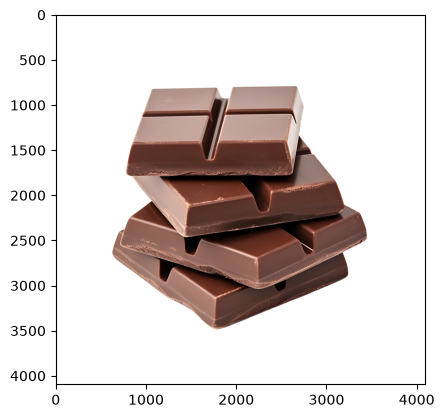

In [15]:
# load dark chocolate image
dark_img = mpimg.imread(
    os.path.join(
        "..", "data", "images",
        "dark_1.png"
    )
)

plt.imshow(dark_img)

In [7]:
# color profile
color_palette = {
    "background":  "#FBF1E3",  # Cream
    "text_1":      "#30231D",  # Espresso brown for main text
    "text_2":      "#705A4F",  # Muted brown for annotations
    "accent_line": "#AB4C2E",  # Terracotta for the accent dash
    "cocoa":       "#79543F",  # Cocoa brown for scatter points

    "grid":       "#E7D9C9",
    "bar_track": "#EBDCCE",
}



In [8]:
# fonts
regular = load_google_font("Balsamiq Sans", weight=400)
italic = load_google_font("Balsamiq Sans", weight=400, italic=True)
bold = load_google_font("Balsamiq Sans", weight=700)

In [9]:
# data
sugar = df["Added Sugar %"]
cocoa = df["Cocoa %"]

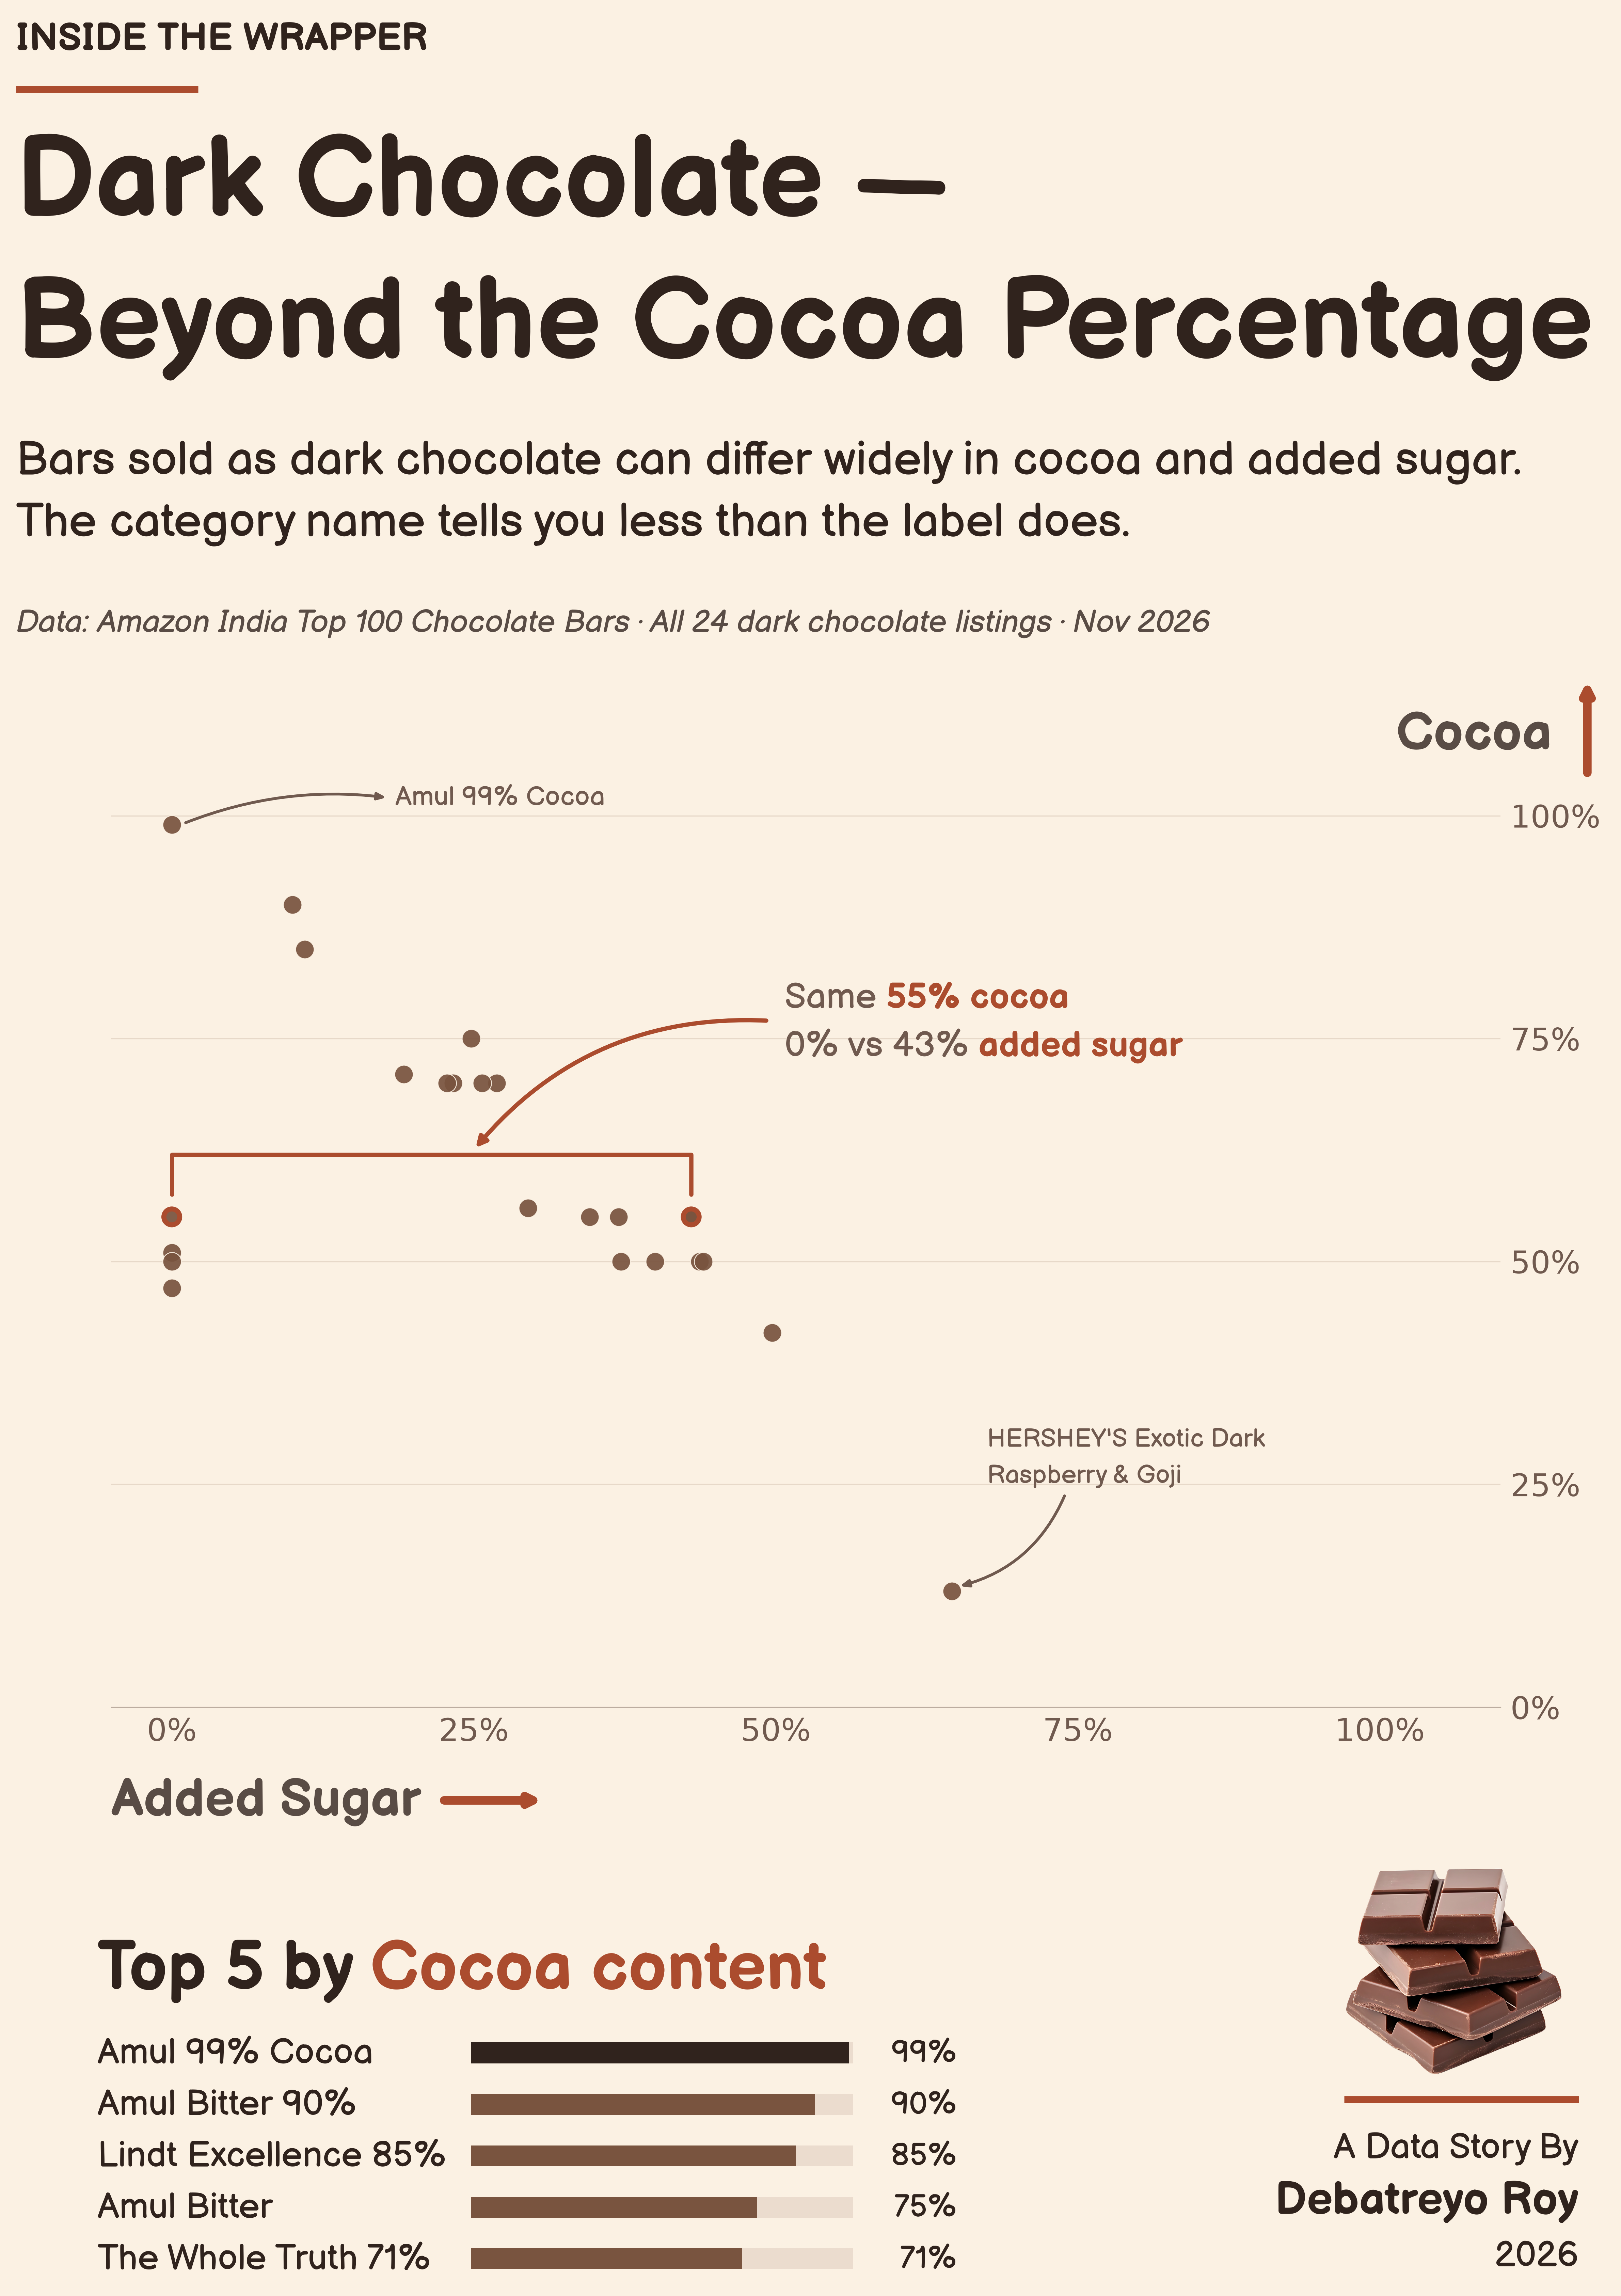

In [64]:
# viz
dpi = 300

fig, ax = plt.subplots(figsize=(17, 24), dpi=dpi)

fig.set_facecolor(color_palette["background"])
ax.set_facecolor(color_palette["background"])

fig.subplots_adjust(left=0.1, right=0.9, top=0.7, bottom=0.3)

############################################

# Title & Subtitles
x_t = 0.045
# title
fig_text(
  x=x_t,
  y=0.99,
  s="INSIDE THE WRAPPER",
  size=27, color=color_palette["text_1"],
  font=bold,
  highlight_textprops=[
      
  ],
)

# short decorative underline
header_line = Line2D(
    [x_t, 0.15],
    [0.96, 0.96],
    color=color_palette["accent_line"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line)

# Sub-title
fig_text(
  x=x_t,
  y=0.95,
  s="Dark Chocolate —\nBeyond the Cocoa Percentage",
  size=80, color=color_palette["text_1"],
  font=bold,
  highlight_textprops=[
      
  ],
)

# explanation
fig_text(
  x=x_t,
  y=0.82,
  s="Bars sold as dark chocolate can differ widely in cocoa and added sugar.\nThe category name tells you less than the label does.",
  size=33, color=color_palette["text_1"],
  font=regular,
  highlight_textprops=[
      
  ],
)

# data source
fig_text(
  x=x_t,
  y=0.75,
  s="Data: Amazon India Top 100 Chocolate Bars · All 24 dark chocolate listings · Nov 2026",
  size=22,
  font=italic,
  color=color_palette["text_1"],
  alpha=0.8
)

############################################

# canvas settings

ax.set_xlim(-5, 110)
ax.set_ylim(0, 110)
# Move y-axis ticks and percentages
ax.yaxis.tick_right()                                       

ax.xaxis.set_major_locator(MultipleLocator(25))
ax.yaxis.set_major_locator(MultipleLocator(25))

ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

ax.tick_params(
    axis="both", which="major", length=0, pad=7,
    labelsize=22, labelcolor=color_palette["text_2"]
)

for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color(color_palette["text_2"])
ax.spines["bottom"].set_alpha(0.45)
ax.spines["bottom"].set_linewidth(0.8)

ax.set_axisbelow(True)
ax.grid(False, axis="x")
ax.grid(
    True, axis="y",
    color=color_palette["grid"], linestyle="-", linewidth=0.8,
)

############################################

# main scatterplot viz

ax.scatter(
    x=sugar,
    y=cocoa,
    s=170,
    color=color_palette["cocoa"],
    edgecolors=color_palette["background"],
    linewidths=0.6,
    alpha=0.93,
    zorder=3,
)

############################################

# main scatterplot annotation driving the narrative

cocoa_level = 55
sugar_low, sugar_high = 0, 43
sugar_gap = sugar_high - sugar_low
bracket_y = 62
accent_color = color_palette["accent_line"]

# Ring the two comparison points without covering the original dots
ax.scatter(
    x=[sugar_low, sugar_high],
    y=[cocoa_level, cocoa_level],
    s=125,
    facecolors="none",
    edgecolors=accent_color,
    linewidths=3.5,
    zorder=5,
)

# Draw the bracket above the points, with short downward ends
ax.plot(
    [sugar_low, sugar_low, sugar_high, sugar_high],
    [cocoa_level + 2.5, bracket_y, bracket_y, cocoa_level + 2.5],
    color=accent_color,
    linewidth=3,
    solid_capstyle="round",
    zorder=4,
)

ax_arrow(
    tail_position=[sugar_gap*1.15, cocoa_level+22], head_position=[sugar_gap//2 + 4, cocoa_level+7.5],
    head_length=6, head_width=3, width=3, fill_head=True,
    color=color_palette["accent_line"], radius=0.25
)
ax_text(
    x=sugar_gap*1.18, y=cocoa_level+27,
    s=f"Same <55% cocoa>\n0% vs 43% <added sugar>", ha="left",
    size=25, font=regular, color=color_palette["text_2"],
    highlight_textprops=[
        dict(color=color_palette["accent_line"], font=bold),
        dict(color=color_palette["accent_line"], font=bold),
    ]
)

############################################

# Annotate interesting outlier products

# HERSHEY'S Exotic Dark Raspberry & Goji = [64.6, 13]
ax_arrow(
    tail_position=[74, 24], head_position=[65, 13.5],
    head_length=5, head_width=2, width=2, fill_head=True,
    color=color_palette["text_2"], radius=-0.25
)
ax_text(
    x=79, y=31.8,
    s="HERSHEY'S Exotic Dark\nRaspberry & Goji",
    size=18, font=regular, color=color_palette["text_2"],
    ha="center"
)
# Amul 99% Cocoa Chocolate = [0, 99]
ax_arrow(
    tail_position=[0.93, 99.1], head_position=[18, 102],
    head_length=5, head_width=2, width=2, fill_head=True,
    color=color_palette["text_2"], radius=-0.13
)
ax_text(
    x=18.5, y=103.9,
    s="Amul 99% Cocoa",
    size=19, font=regular, color=color_palette["text_2"],
    ha="left"
)

############################################

# custom axis labels

fig_text(
  x=0.84,
  y=0.71,
  s="Cocoa",
  size=37,
  font=bold,
  color=color_palette["text_1"],
  alpha=0.8
)
fig_arrow(
    tail_position=[0.95, 0.68], head_position=[0.95, 0.72],
    head_length=6, head_width=3, width=6, fill_head=True,
    color=color_palette["accent_line"]
)

fig_text(
  x=0.1,
  y=0.275,
  s="Added Sugar",
  size=37,
  font=bold,
  color=color_palette["text_1"],
  alpha=0.8
)
fig_arrow(
    tail_position=[0.29, 0.262], head_position=[0.35, 0.262],
    head_length=6, head_width=3, width=6, fill_head=True,
    color=color_palette["accent_line"]
)

############################################

# Bottom element 1 - top 5 cocoa % products

name_col = "Name"
cocoa_col = "Cocoa %"

top_cocoa = df.nlargest(5, cocoa_col)[[name_col, cocoa_col]]

# display names of top 5 cocoa % chocolates to keep long product names from crowding the bars
short_names = {
    "Amul 99% Cocoa Chocolate": "Amul 99% Cocoa",
    "AMUL Bitter 90% Chocolate": "Amul Bitter 90%",
    "Lindt Excellence 85% Cocoa Extra Fine Dark Chocolate": "Lindt Excellence 85%",
    "AMUL Bitter Chocolate": "Amul Bitter",
    "The Whole Truth - 71% Dark Cocoa": "The Whole Truth 71%",
}

# Layout in figure coordinates, where 0 and 1 are the figure edges
label_x = 0.092
bar_x = 0.307
value_x = 0.577

title_y = 0.21
first_row_y = 0.159
row_gap = 0.021

bar_width = 0.220
bar_height = 0.0085


fig_text(
    x=label_x, y=title_y,
    s="Top 5 by <Cocoa content>",
    font=bold, size=48,
    color=color_palette["text_1"],
    highlight_textprops=[
        dict(color=color_palette["accent_line"])
    ]
)

for rank, (name, cocoa_pct) in enumerate(
    top_cocoa.itertuples(index=False, name=None)
):
    row_y = first_row_y - rank * row_gap
    bar_bottom = row_y - bar_height / 2
    fill_width = bar_width * cocoa_pct / 100
    fill_color = color_palette["text_1"] if rank == 0 else color_palette["cocoa"]
    display_name = short_names.get(name.strip(), name)

    # Draw the 100% track first, then the measured cocoa share
    for width, face_color in (
        (bar_width, color_palette["bar_track"]),
        (fill_width, fill_color),
    ):
        fig.add_artist(
            Rectangle(
                (bar_x, bar_bottom),
                width, bar_height,
                transform=fig.transFigure,
                facecolor=face_color,
                edgecolor="none",
            )
        )


    fig_text(
    x=label_x, y=row_y,
    s=display_name,
    font=regular, size=25, ha="left", va="center",
    color=color_palette["text_1"],
    highlight_textprops=[
        
    ]
    )
    fig_text(
        x=value_x+0.01, y=row_y,
        s=f"{cocoa_pct:g}%",
        font=regular, size=22,
        ha="right", va="center",
        color=color_palette["text_1"]
    )

############################################

# Bottom element 2 - Dark chocolate image

# [left starting, bottom starting, image width, image height] in figure coordinates
img_ax = fig.add_axes([0.7835, 0.105, 0.18, 0.18])
img_ax.imshow(dark_img, aspect="equal", interpolation="lanczos")
img_ax.axis("off")

############################################

# Bottom element 3 - Signature

# short decorative underline
header_line_sign = Line2D(
    [0.81, 0.945],
    [0.14, 0.14],
    color=color_palette["accent_line"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line_sign)

fig_text(
    x=0.945, y=0.129,
    s="A Data Story By",
    size=25, font=regular,
    color=color_palette["text_1"],
    ha="right"
)
fig_text(
    x=0.945, y=0.11,
    s="Debatreyo Roy",
    size=32, font=bold,
    color=color_palette["text_1"],
    ha="right"
)
fig_text(
    x=0.945, y=0.085,
    s="2026",
    size=25, font=regular,
    color=color_palette["text_1"],
    ha="right"
)

############################################

save_path = os.path.join(
    "..", "viz",
    "dark_chocolate.jpeg"
)

plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=2)

---